# TD 4 : représenter un son

**BUT INFO3 Développeur IA, R5.C.08, IA5, Partie 1**
M. Sakkari, IUT de La Rochelle

> **À rendre :** les cellules « À vous » complétées, dans votre dépôt GitLab.

## Dans ce TD, on apprend à...
- **lire** un fichier son et comprendre qu'il contient simplement une suite de nombres ;
- **dessiner** un son de deux façons : sa forme d'onde, puis son spectrogramme ;
- **résumer** chaque son par quelques nombres pour obtenir un tableau, comme on l'a fait pour le texte au TD 1 ;
- **reconnaître une personne** par sa voix, et savoir à quel point on peut s'y fier.

## Les données
**FSDD** (*Free Spoken Digit Dataset*, « jeu libre de chiffres prononcés ») : des enregistrements de chiffres de 0 à 9 prononcés en anglais. Le jeu complet compte 3 000 enregistrements de 6 personnes. On utilise un échantillon de **60 fichiers** : 10 chiffres, 3 personnes (`george`, `jackson`, `lucas`) et 2 prononciations chacune.

Le nom d'un fichier donne tout : `0_george_1.wav` veut dire « chiffre 0, prononcé par george, deuxième prononciation (numéro 1) ».

Référence : [Free Spoken Digit Dataset](https://github.com/Jakobovski/free-spoken-digit-dataset).

> **Comment travailler :** une cellule « Démo » est déjà écrite, il faut la lancer et la lire. Une cellule « À vous » est à compléter : remplacez les `...` par votre code. **Exécutez les cellules dans l'ordre, de haut en bas.** Si vous redémarrez le noyau (le programme Python qui exécute les cellules), relancez d'abord la première cellule de code, celle qui charge les outils.

## Petit lexique avant de commencer

Ces mots reviennent dans tout le TD. Ils sont aussi expliqués au moment où on s'en sert.

| Mot | Ce que ça veut dire | Exemple |
|---|---|---|
| **Signal** | la suite de nombres qui représente un son | les mesures d'un enregistrement |
| **Mesure** (ou **échantillon**) | un nombre qui indique la force du signal à un instant | 0,12 |
| **Fréquence d'échantillonnage** | le nombre de mesures par seconde, en **hertz (Hz)** | 8 000 Hz = 8 000 mesures par seconde |
| **ms** (milliseconde) | un millième de seconde | 5 ms = 0,005 s |
| **Fréquence d'un son** | la vitesse à laquelle l'air vibre, en Hz : une basse fréquence donne un son **grave**, une haute fréquence donne un son **aigu** | 100 Hz : son grave ; 3 000 Hz : son aigu |
| **Intensité** (d'une fréquence) | la force d'une fréquence dans le son : plus elle est grande, plus on entend cette fréquence | 200 Hz d'intensité 3 et 1 000 Hz d'intensité 1 : le 200 Hz est trois fois plus fort |
| **Spectre** | la liste des intensités de toutes les fréquences d'un son, à un instant donné | un dessin avec la fréquence en abscisse et l'intensité en ordonnée (schéma de la partie 2) |
| **Spectrogramme** | un dessin qui montre quelles fréquences sont présentes dans un son, et à quel moment | partie 2 |
| **Descripteur** | un nombre qui résume une propriété d'un son | sa durée, sa force moyenne |
| **Locuteur** | la personne qui parle | george, jackson ou lucas |

In [1]:
# Objectif : charger les outils et lister les fichiers son.

import wave                          # module Python qui sait lire les fichiers .wav
import glob, os                      # glob cherche des fichiers, os manipule les noms de fichiers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dossier contenant les fichiers de données
DATA = "../data"
DOSSIER_AUDIO = f"{DATA}/audio_fsdd_sample"

# glob.glob trouve tous les fichiers .wav ; sorted les range par ordre alphabétique
fichiers = sorted(glob.glob(f"{DOSSIER_AUDIO}/*.wav"))
print("Nombre de fichiers :", len(fichiers))
print("Exemples :", [os.path.basename(f) for f in fichiers[:3]])

Nombre de fichiers : 60
Exemples : ['0_george_0.wav', '0_george_1.wav', '0_jackson_0.wav']


# Partie 1 : Un son est une suite de nombres

### Concept

Un microphone mesure la pression de l'air des milliers de fois par seconde, et note chaque mesure par un nombre. Un son enregistré est donc **une longue suite de nombres**.

Au TD 1, un avis devenait une ligne de nombres. Ici, un son devient une suite de nombres, plus longue : environ 4 000 nombres pour un son d'une demi-seconde.

**Pourquoi y a-t-il des valeurs négatives ?** Un son est une vibration autour d'une position de repos, et le repos correspond à la valeur 0. Quand le son vibre, la pression de l'air passe tantôt au-dessus du repos (mesure positive), tantôt en dessous (mesure négative). Le signe indique donc seulement de quel côté du repos on se trouve, pas si le son est fort ou faible. C'est la distance à 0 (la valeur absolue) qui donne la force du son : +0,3 et -0,3 sont aussi forts l'un que l'autre.

| Mot | Ce que ça veut dire | Exemple |
|---|---|---|
| **Mesure** | un nombre qui indique la force du signal à un instant | 0,12 |
| **Fréquence d'échantillonnage** | le nombre de mesures par seconde, en **hertz (Hz)** | 8 000 Hz = 8 000 mesures par seconde |
| **Amplitude** | la valeur d'une mesure : plus elle est loin de 0, plus le son est fort à cet instant | -0,3 ou +0,3 : son fort |
| **Durée** | nombre de mesures ÷ fréquence d'échantillonnage | 4 000 mesures à 8 000 Hz = 0,5 s |
| **Forme d'onde** | le dessin des mesures au cours du temps | |

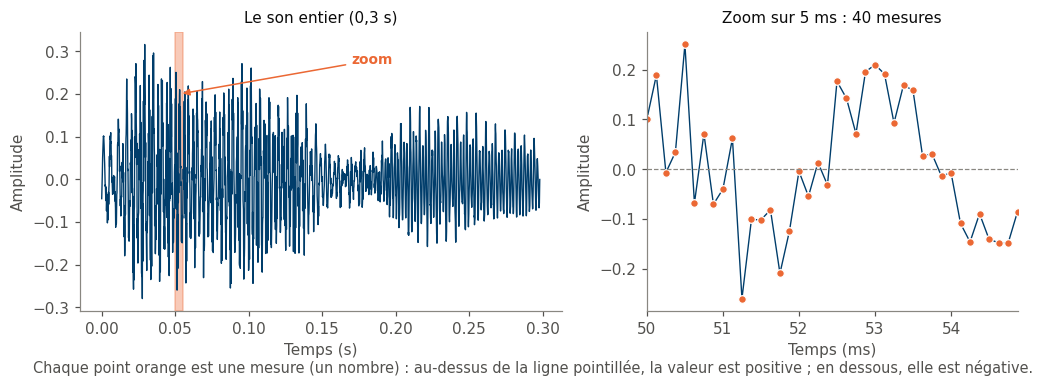

### Démo : lire un son

La fonction `lire_son` renvoie les mesures du son et sa fréquence d'échantillonnage.

In [2]:
# Objectif : lire un fichier son et obtenir ses mesures.

def lire_son(chemin):
    with wave.open(chemin) as w:
        frequence = w.getframerate()            # nombre de mesures par seconde (en Hz)
        octets = w.readframes(w.getnframes())   # toutes les mesures, en octets bruts
    # np.frombuffer transforme les octets en nombres entiers codés sur 16 bits (int16)
    mesures = np.frombuffer(octets, dtype=np.int16)
    # On divise par 32768 pour obtenir des valeurs comprises entre -1 et 1
    signal = mesures / 32768.0
    return signal, frequence


# Exemple : le chiffre 0 prononcé par george (première prononciation)
signal, frequence = lire_son(f"{DOSSIER_AUDIO}/0_george_0.wav")
print("Fréquence d'échantillonnage :", frequence, "Hz")
print("Nombre de mesures :", len(signal))
print("Durée :", round(len(signal) / frequence, 3), "s")
print("Cinq premières mesures :", signal[:5].round(4))
print("Minimum et maximum :", round(signal.min(), 3), round(signal.max(), 3))

Fréquence d'échantillonnage : 8000 Hz
Nombre de mesures : 2384
Durée : 0.298 s
Cinq premières mesures : [-0.0454 -0.0294 -0.0185  0.005   0.0315]
Minimum et maximum : -0.28 0.316


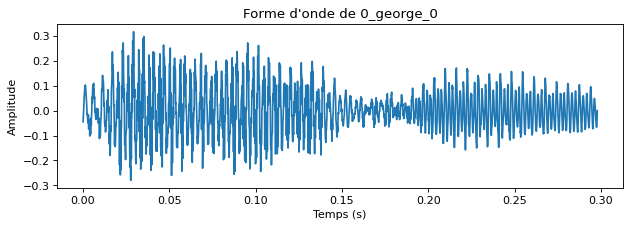

In [3]:
# Objectif : dessiner la forme d'onde du son (les mesures au cours du temps).

# Instant de chaque mesure, en secondes : numéro de la mesure ÷ fréquence d'échantillonnage
temps = np.arange(len(signal)) / frequence

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(temps, signal)
ax.set_xlabel("Temps (s)")
ax.set_ylabel("Amplitude")
ax.set_title("Forme d'onde de 0_george_0")
plt.tight_layout()
plt.show()

**Lecture du résultat.** Le fichier `0_george_0` contient **2 384 mesures** enregistrées à **8 000 Hz**. Il dure donc 2 384 ÷ 8 000 = **0,298 s**. Les mesures sont comprises entre -0,280 et 0,316.

Sur le dessin, on voit que le son est plus fort au début du mot qu'à la fin.

### À vous : la durée des 60 sons

On veut savoir si tous les sons ont à peu près la même durée.

**À faire :** calculez la durée de chacun des 60 fichiers, puis trouvez le plus court, le plus long, et la durée moyenne.

**Questions :**
1. Quel est le son le plus court ? Le plus long ?
2. Un son contient 4 000 mesures. Combien de temps dure-t-il ? Que vous manque-t-il pour répondre ?

In [4]:
# Objectif : calculer la durée de chacun des 60 sons.

durees = {}
for chemin in fichiers:
    signal, frequence = lire_son(chemin)
    # Durée en secondes = nombre de mesures ÷ fréquence d'échantillonnage
    durees[os.path.basename(chemin)] = len(signal) / frequence

durees = pd.Series(durees)

# idxmin() et idxmax() donnent le nom du fichier le plus court et le plus long,
# min() et max() donnent leurs durées, mean() donne la durée moyenne
plus_court, duree_min = durees.idxmin(), durees.min().round(3)
plus_long, duree_max = durees.idxmax(), durees.max().round(3)
duree_moyenne = durees.mean().round(3)

print("Plus court :", plus_court, duree_min, "s")
print("Plus long  :", plus_long, duree_max, "s")
print("Durée moyenne :", duree_moyenne, "s")

Plus court : 0_george_0.wav 0.298 s
Plus long  : 5_lucas_1.wav 1.147 s
Durée moyenne : 0.533 s


### Réponse

1. Le son le plus court est `0_george_0.wav` (0,298 s), le plus long est `5_lucas_1.wav` (1,147 s). La durée moyenne est de 0,533 s. Les sons ne durent donc pas tous pareil : le plus long dure environ 3,8 fois le plus court. Ils ont des nombres de mesures différents, et c'est pour cela qu'on ne peut pas les comparer directement, mesure par mesure.
2. On ne peut pas le dire. Il manque **le nombre de mesures faites par seconde** : c'est la **fréquence d'échantillonnage**. À 8 000 Hz, 4 000 mesures durent 4 000 ÷ 8 000 = 0,5 s. À 44 100 Hz (la fréquence d'un CD audio), elles durent environ 0,09 s. Il faut donc toujours diviser le nombre de mesures par la fréquence d'échantillonnage.

# Partie 2 : Voir un son, le spectrogramme

### Concept

La forme d'onde dit **quand** le son est fort, mais pas **de quoi** il est fait : un son grave et un son aigu peuvent avoir la même forme d'onde en gros.

Un son est un mélange de **fréquences**. Une fréquence est la vitesse à laquelle l'air vibre, en hertz (Hz) : les basses fréquences donnent les sons **graves**, les hautes fréquences les sons **aigus**.

Le **spectrogramme** montre quelles fréquences sont présentes, et à quel moment :
1. on découpe le son en petites tranches de temps (ici 256 mesures, soit 32 ms à 8 000 Hz) ;
2. pour chaque tranche, on calcule l'intensité de chaque fréquence (calcul appelé **FFT**, *Fast Fourier Transform*, « transformée de Fourier rapide ») ;
3. on dessine le résultat : le temps en abscisse, la fréquence en ordonnée, et l'intensité en couleur (plus clair = plus intense).

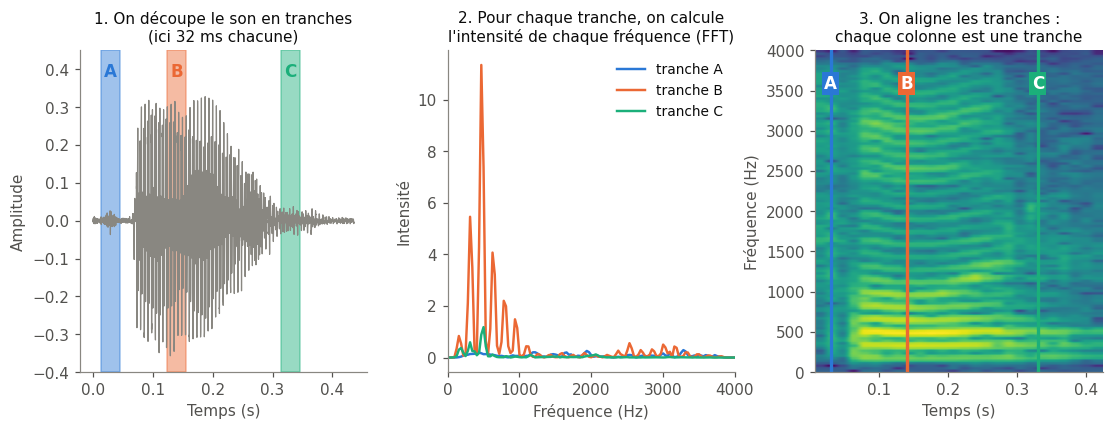

Sur ce schéma, la tranche A tombe dans le silence du début, la tranche B dans la partie la plus forte du mot, et la tranche C dans la fin du mot, qui s'affaiblit. Le spectre de la tranche B montre des pics nets à basse fréquence : ce sont les bandes claires du spectrogramme.

> **Limite à retenir :** avec une fréquence d'échantillonnage de 8 000 Hz, on ne peut voir que les fréquences jusqu'à **4 000 Hz**, c'est-à-dire la moitié de la fréquence d'échantillonnage (règle dite de Nyquist-Shannon).

Références : [documentation de `specgram` (Matplotlib)](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.specgram.html) ; M. Müller, [*Fundamentals of Music Processing*](https://www.audiolabs-erlangen.de/fau/professor/mueller/bookFMP), Springer, 2015, chapitre 2.

### Démo : le chiffre 4

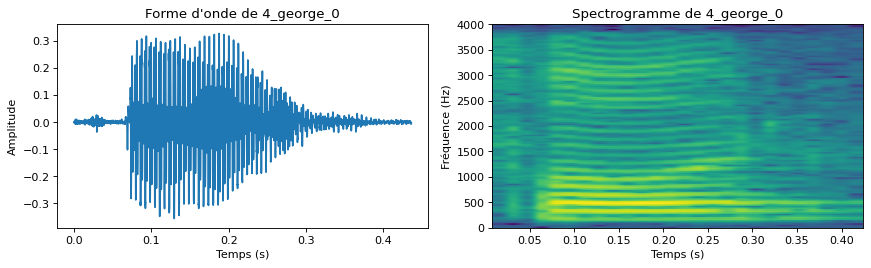

In [5]:
# Objectif : voir le chiffre 4 de deux façons : forme d'onde et spectrogramme.

signal, frequence = lire_son(f"{DOSSIER_AUDIO}/4_george_0.wav")
temps = np.arange(len(signal)) / frequence

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

# À gauche : la forme d'onde
axes[0].plot(temps, signal)
axes[0].set_xlabel("Temps (s)")
axes[0].set_ylabel("Amplitude")
axes[0].set_title("Forme d'onde de 4_george_0")

# À droite : le spectrogramme
# NFFT=256 : chaque tranche contient 256 mesures (32 ms à 8 000 Hz)
# noverlap=128 : deux tranches voisines se chevauchent de moitié, pour un dessin plus lisse
axes[1].specgram(signal, NFFT=256, Fs=frequence, noverlap=128, cmap="viridis")
axes[1].set_xlabel("Temps (s)")
axes[1].set_ylabel("Fréquence (Hz)")
axes[1].set_title("Spectrogramme de 4_george_0")

plt.tight_layout()
plt.show()

**Lecture du résultat.**
- Pendant les 0,07 premières secondes, le son est presque nul : la forme d'onde est plate et le spectrogramme est sombre.
- Ensuite, on voit des **bandes claires horizontales** : ce sont les fréquences où l'intensité est forte. Les plus fortes sont en dessous d'environ 1 000 Hz.

### À vous : comparer avec le chiffre 6

**À faire :** dessinez le spectrogramme de `6_george_0.wav`, avec le même code que dans la démo.

**Questions :**
1. Où sont les fréquences les plus intenses sur ce spectrogramme, par rapport à celui du chiffre 4 : plutôt dans les graves ou dans les aiguës ?
2. Vers 0,37 s, on voit une courte barre verticale. Elle correspond à un bruit très bref dans le mot. Le mot prononcé est « six ». À quel moment du mot, à votre avis, entend-on ce bruit ?

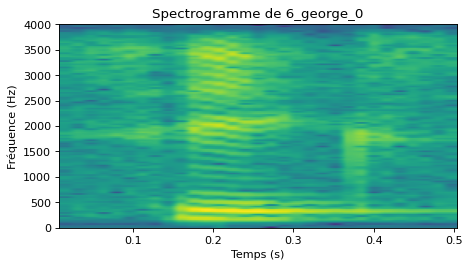

In [6]:
# Objectif : dessiner le spectrogramme du chiffre 6 pour le comparer à celui du chiffre 4.

# On lit le fichier 6_george_0.wav
signal, frequence = lire_son(f"{DOSSIER_AUDIO}/6_george_0.wav")

# Même spectrogramme que dans la démo
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.specgram(signal, NFFT=256, Fs=frequence, noverlap=128, cmap="viridis")
ax.set_xlabel("Temps (s)")
ax.set_ylabel("Fréquence (Hz)")
ax.set_title("Spectrogramme de 6_george_0")
plt.tight_layout()
plt.show()

### Réponse

1. Pour le chiffre 4, les fréquences les plus intenses sont surtout en dessous de 1 000 Hz. Pour le chiffre 6, il y a aussi des fréquences intenses plus aiguës : des bandes claires apparaissent vers 2 000 Hz et entre 3 000 et 3 500 Hz, au moment où le mot est le plus fort (autour de 0,2 s). Le chiffre 6 a donc un contenu plus aigu que le chiffre 4.
2. La courte barre verticale vers 0,37 s est un **bruit bref** : il contient beaucoup de fréquences en même temps, d'où une barre qui monte sur plusieurs milliers de hertz. Elle correspond probablement à la fin du mot *six* (le son « x »). Seul le spectrogramme montre cela : la forme d'onde montre bien une petite pointe à cet endroit, mais ne dit pas de quelles fréquences elle est faite.

# Partie 3 : Résumer chaque son par quelques nombres

### Concept

Les 60 sons n'ont pas la même durée : ils n'ont donc pas le même nombre de mesures, et on ne peut pas les ranger dans un tableau tel quel. On résume alors **chaque son par quelques nombres**, appelés **descripteurs**. C'est la même idée que pour le texte au TD 1 : un avis devenait quelques nombres (longueur, nombre de mots...).

On utilise quatre descripteurs :

| Descripteur | Ce qu'il mesure | Exemple de calcul |
|---|---|---|
| **Durée** | la longueur du son, en secondes | 4 000 mesures ÷ 8 000 Hz = 0,5 s |
| **RMS** (*Root Mean Square*, « racine de la moyenne des carrés ») | la force moyenne du son | mesures 0,3 et -0,4 : carrés 0,09 et 0,16 ; moyenne 0,125 ; racine 0,35 |
| **ZCR** (*Zero Crossing Rate*, « taux de passage par zéro ») | la part des paires de mesures voisines où le signal change de signe : élevé si le signal oscille très vite ou s'il ressemble à du souffle | mesures 0,2 ; -0,1 ; -0,3 ; 0,4 ; 0,5 : signes + - - + +. On regarde les 4 paires de mesures voisines, de signes (+ -), (- -), (- +) et (+ +) : le signe change dans 2 d'entre elles (la 1re et la 3e), donc ZCR = 2 ÷ 4 = 0,5 |
| **Centroïde** (*spectral centroid*, « fréquence moyenne ») | la fréquence moyenne du son, chaque fréquence comptant selon son intensité : élevé pour un son aigu | fréquence 200 Hz d'intensité 3 et 1 000 Hz d'intensité 1 : (200×3 + 1 000×1) ÷ 4 = 400 Hz |

**Le ZCR en image.** On regarde si la courbe traverse la ligne du 0 entre deux mesures voisines :

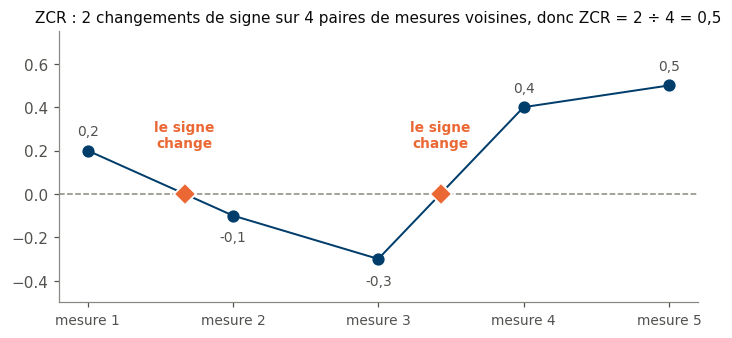

**Le centroïde en image.** C'est le « milieu de gravité » du spectre. Ici, le même chiffre 4 prononcé par deux personnes : le centroïde est plus haut pour george que pour jackson.

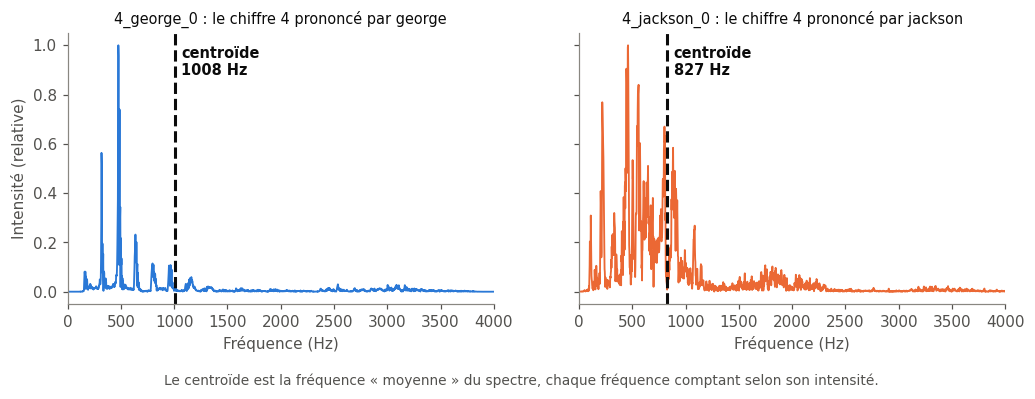

### À vous : le taux de passage par zéro

**À faire :** calculez le ZCR du petit signal de l'exemple (les 5 mesures `0,2 ; -0,1 ; -0,3 ; 0,4 ; 0,5`, vous devez trouver 0,5), puis celui du son `0_george_0`.

**Questions :**
1. Quel ZCR trouvez-vous pour `0_george_0` ?
2. Sur 100 paires de mesures voisines de ce son, dans combien environ le signe change-t-il ?

In [7]:
# Objectif : calculer le ZCR (taux de passage par zéro) d'un signal.

petit = np.array([0.2, -0.1, -0.3, 0.4, 0.5])

# Étape 1 : np.sign donne le signe de chaque mesure (-1, 0 ou +1)
signes = np.sign(petit)

# Étape 2 : np.diff donne la différence entre deux signes voisins.
#           Elle est différente de 0 quand le signe change.
differences = np.diff(signes)

# Étape 3 : on compte la part des paires où le signe change
#           (abs(...) > 0 donne True quand il y a un changement, puis mean() donne la part)
zcr_petit = np.mean(np.abs(differences) > 0)
print("Taux de passage par zéro (ZCR) du petit signal :", zcr_petit)   # résultat attendu : 0.5

# Même calcul pour le son 0_george_0
signal, frequence = lire_son(f"{DOSSIER_AUDIO}/0_george_0.wav")
zcr_son = np.mean(np.abs(np.diff(np.sign(signal))) > 0)
print("Taux de passage par zéro (ZCR) de 0_george_0 :", round(zcr_son, 3))

Taux de passage par zéro (ZCR) du petit signal : 0.5
Taux de passage par zéro (ZCR) de 0_george_0 : 0.16


### Réponse

Le petit signal a les signes `+ - - + +`, donc la suite des différences est `-2, 0, +2, 0` : le signe change sur 2 paires sur 4, soit un ZCR de **0,5**.

1. Le ZCR de `0_george_0` est de **0,160**.
2. Le signe change dans environ **16** paires sur 100. Plus le ZCR est grand, plus le signal oscille vite (ou ressemble à du souffle) ; plus il est petit, plus le signal reste longtemps du même côté de zéro.

### Démo : un tableau de descripteurs pour les 60 sons

On range la fonction qui calcule les quatre descripteurs dans `descripteurs`, puis on l'applique à chaque fichier. On obtient un **tableau de 60 lignes** : une ligne par son, comme une ligne par avis au TD 1.

In [8]:
# Objectif : résumer un son par quatre nombres (durée, RMS, ZCR, centroïde).

def descripteurs(signal, frequence):
    # Durée en secondes
    duree = len(signal) / frequence

    # RMS : racine de la moyenne des carrés des mesures
    rms = np.sqrt(np.mean(signal ** 2))

    # ZCR : part des paires de mesures voisines dont le signe change
    zcr = np.mean(np.abs(np.diff(np.sign(signal))) > 0)

    # Centroïde : fréquence moyenne, pondérée par l'intensité de chaque fréquence
    # np.fft.rfft calcule l'intensité de chaque fréquence (c'est la FFT vue plus haut)
    # np.fft.rfftfreq donne la valeur en Hz de chaque fréquence
    intensites = np.abs(np.fft.rfft(signal))
    frequences = np.fft.rfftfreq(len(signal), d=1 / frequence)
    centroide = np.sum(frequences * intensites) / np.sum(intensites)

    return {"duree": duree, "rms": rms, "zcr": zcr, "centroide": centroide}


# On applique la fonction à chaque fichier
lignes = []
for chemin in fichiers:
    nom = os.path.basename(chemin)
    # "0_george_0.wav" -> chiffre "0", locuteur "george", numéro "0"
    chiffre, locuteur, numero = nom[:-4].split("_")
    signal, frequence = lire_son(chemin)

    ligne = descripteurs(signal, frequence)
    ligne.update({"fichier": nom, "chiffre": int(chiffre), "locuteur": locuteur})
    lignes.append(ligne)

DESCRIPTEURS = ["duree", "rms", "zcr", "centroide"]
tableau = pd.DataFrame(lignes)[["fichier", "chiffre", "locuteur"] + DESCRIPTEURS]
print("Dimensions :", tableau.shape)
tableau.head()

Dimensions : (60, 7)


,fichier,chiffre,locuteur,duree,rms,zcr,centroide
0,0_george_0.wav,0,george,0.298000,0.088870,0.160302,1566.826917
1,0_george_1.wav,0,george,0.590875,0.050029,0.123995,1235.720690
2,0_jackson_0.wav,0,jackson,0.643500,0.136793,0.096173,849.741112
3,0_jackson_1.wav,0,jackson,0.532625,0.101158,0.093427,654.406739
4,0_lucas_0.wav,0,lucas,0.635375,0.053934,0.246556,1071.007312


In [9]:
# Résumé de chaque descripteur : moyenne, écart-type, minimum et maximum
tableau[DESCRIPTEURS].describe().round(3)

,duree,rms,zcr,centroide
count,60.000,60.000,60.000,60.000
mean,0.533,0.068,0.213,1133.428
std,0.151,0.023,0.087,301.668
min,0.298,0.030,0.093,654.407
25%,0.435,0.052,0.157,921.944
50%,0.516,0.065,0.189,1074.770
75%,0.590,0.075,0.254,1306.421
max,1.147,0.137,0.428,1918.285


**Lecture du tableau.** Chaque son est maintenant décrit par 4 nombres au lieu d'environ 4 262 mesures.
- `duree` : 0,533 s en moyenne, entre 0,298 s et 1,147 s ;
- `rms` : 0,068 en moyenne (la valeur maximale possible d'une mesure est 1) ;
- `zcr` : 0,213 en moyenne, entre 0,093 et 0,428 ;
- `centroide` : 1 133 Hz en moyenne, entre 654 Hz et 1 918 Hz.

# Partie 4 : Reconnaître une personne par sa voix

### Concept

Le tableau contient une étiquette qui nous intéresse : le **locuteur** (la personne qui parle). On peut se demander si les descripteurs permettent de distinguer les personnes. Pour le voir, on calcule la **moyenne de chaque descripteur pour chaque personne**, avec `groupby`, comme au TD 2. Puis on regarde si les moyennes sont **très différentes** d'une personne à l'autre.

### Démo

In [10]:
# Objectif : comparer la moyenne de chaque descripteur selon le locuteur.

# groupby range les lignes en paquets (un paquet par locuteur), puis mean() fait la moyenne de chaque paquet
par_locuteur = tableau.groupby("locuteur")[DESCRIPTEURS].mean().round(3)

print("Moyennes par locuteur (20 sons par locuteur) :")
print(par_locuteur)

Moyennes par locuteur (20 sons par locuteur) :
          duree    rms    zcr  centroide
locuteur                                
george    0.512  0.064  0.206   1435.022
jackson   0.512  0.079  0.171    917.925
lucas     0.574  0.061  0.263   1047.336


**Lecture du résultat.** Selon la personne, le **centroïde** moyen change beaucoup : 918 Hz pour jackson, 1 435 Hz pour george. La **durée** moyenne change peu : 0,512 s pour george et jackson, 0,574 s pour lucas.

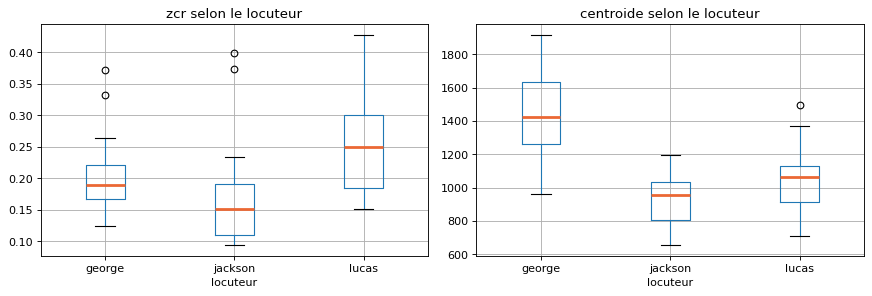

In [11]:
# Objectif : voir toute la répartition, pas seulement la moyenne (boîtes à moustaches).

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Un graphique par descripteur (zcr puis centroide), une boîte par locuteur
for ax, descripteur in zip(axes, ["zcr", "centroide"]):
    # medianprops : la médiane est tracée en orange, comme sur le schéma plus bas
    tableau.boxplot(column=descripteur, by="locuteur", ax=ax,
                    medianprops=dict(color="#eb6834", linewidth=2.5))
    ax.set_title(f"{descripteur} selon le locuteur")
    ax.set_xlabel("locuteur")

plt.suptitle("")   # enlève le titre automatique ajouté par pandas
plt.tight_layout()
plt.show()

**Comment lire une boîte à moustaches.** Une boîte résume un groupe de sons. Le schéma montre les 20 sons de jackson : d'abord un point par son, coupés en quatre quarts de 5 sons, puis la même chose en boîte.

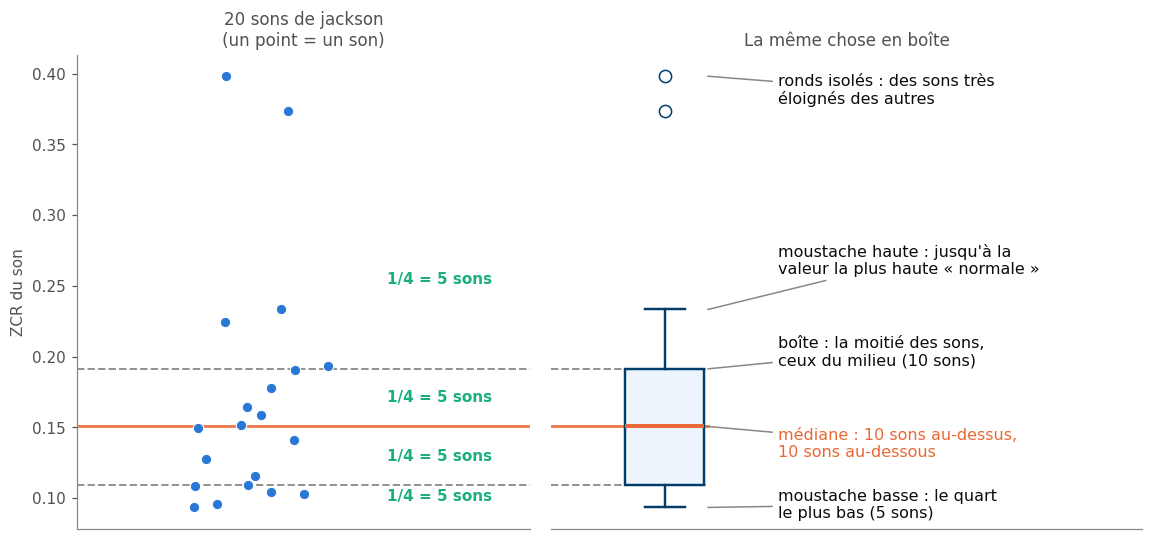

- La **ligne orange** dans la boîte est la **médiane** : la moitié des sons est au-dessus, la moitié au-dessous. Elle n'est pas toujours au centre de la boîte.
- La **boîte** contient la moitié des sons, ceux du milieu : un quart des sons est en dessous de la boîte, un quart au-dessus.
- Les **moustaches** montrent jusqu'où vont les autres valeurs. Avec les ronds isolés, chaque moustache représente un quart des sons.
- Un **rond isolé** est un son très éloigné des autres.

Pour comparer deux groupes, on regarde si leurs boîtes **se chevauchent**. Si elles ne se chevauchent pas, les deux groupes se distinguent bien. Si elles se chevauchent beaucoup, les groupes se ressemblent.

**Lecture du résultat.**
- *Centroïde selon le locuteur* : la boîte de george (de 1 262 à 1 634 Hz) est entièrement au-dessus de celle de jackson (de 808 à 1 035 Hz). Elles ne se chevauchent pas : le centroïde distingue bien george et jackson.
- *ZCR selon le locuteur* : les boîtes des trois personnes se chevauchent. Le ZCR seul distingue mal les personnes.

### Démo : les 60 sons sur un seul dessin

Chaque son est un point, placé selon deux de ses descripteurs : le ZCR (axe horizontal) et le centroïde (axe vertical). On colore chaque point selon le locuteur. Le dessin montre ainsi **60 points**, un par son.

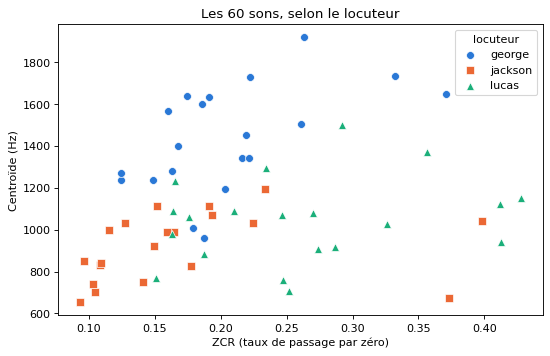

In [12]:
# Objectif : voir les 60 sons sur un même dessin, colorés selon le locuteur.

fig, ax = plt.subplots(figsize=(7, 4.6))

# Une couleur ET une forme par locuteur (la forme aide quand les couleurs se ressemblent)
styles = {"george": ("#2a78d6", "o"), "jackson": ("#eb6834", "s"), "lucas": ("#1baf7a", "^")}

# Un point par son : ZCR en horizontal, centroïde en vertical, coloré selon le locuteur
for nom, (couleur, forme) in styles.items():
    sous_tableau = tableau[tableau["locuteur"] == nom]
    ax.scatter(sous_tableau["zcr"], sous_tableau["centroide"], c=couleur, marker=forme,
               s=50, edgecolors="white", linewidths=0.6, label=nom)
ax.set_title("Les 60 sons, selon le locuteur")
ax.legend(title="locuteur")
ax.set_xlabel("ZCR (taux de passage par zéro)")
ax.set_ylabel("Centroïde (Hz)")
plt.tight_layout()
plt.show()

**Lecture du résultat.** Les trois personnes occupent des zones différentes :
- george : 18 points sur 20 ont un centroïde au-dessus de 1 100 Hz (voix plus aiguë dans ce jeu de données) ;
- jackson : 17 points sur 20 ont un centroïde au-dessous de 1 100 Hz ;
- lucas : 14 points sur 20 ont un ZCR supérieur à 0,2 : ils sont plutôt à droite.

> **À retenir :** avec ces deux descripteurs, on distingue assez bien les **personnes**. Prudence : on ne dispose que de 60 sons, et le ZCR est calculé sur tout le fichier, y compris les moments de souffle ou de bruit de fond où le signe change très souvent.

### Démo : les descripteurs sont-ils liés entre eux ?

Deux descripteurs très liés se répètent : l'un apporte presque la même information que l'autre (c'est la **redondance**, vue au TD 3). La **matrice de corrélation** (`corr()`, comme au TD 1) donne, pour chaque paire de descripteurs, un nombre entre -1 et 1. Plus il est loin de 0, plus les deux descripteurs sont liés.

In [13]:
# Objectif : voir si certains descripteurs se répètent.

# Matrice de corrélation des quatre descripteurs, arrondie à 2 chiffres
correlations = tableau[DESCRIPTEURS].corr().round(2)
correlations

,duree,rms,zcr,centroide
duree,1.00,-0.09,0.47,-0.02
rms,-0.09,1.00,-0.22,-0.32
zcr,0.47,-0.22,1.00,0.23
centroide,-0.02,-0.32,0.23,1.00


**Question :** quelle paire de descripteurs est la plus liée ?

### Réponse

La paire la plus liée est **durée et ZCR** (corrélation de 0,47). Aucune paire ne dépasse 0,5 en valeur absolue : les quatre descripteurs ne se répètent donc pas beaucoup, et il n'y a pas de colonne à supprimer. C'est très différent des 500 colonnes de mots du TD 3, où beaucoup de colonnes se répétaient.

### Démo : quel descripteur sépare le mieux george et jackson ?

On garde seulement les sons de george et de jackson : **40 sons** (20 chacun). Pour chaque descripteur, on applique une règle simple avec un **seuil** (une valeur limite) : on place le seuil au milieu entre la moyenne de george et celle de jackson, et on compte les sons bien classés.

In [14]:
# Objectif : voir quel descripteur sépare le mieux george et jackson, avec un seuil.

# On garde seulement les sons de george et de jackson
deux = tableau[tableau["locuteur"].isin(["george", "jackson"])]
est_george = deux["locuteur"] == "george"                    # True si le son est de george
moyennes = deux.groupby("locuteur")[DESCRIPTEURS].mean()     # moyenne de chaque descripteur pour chaque personne
moy_george = moyennes.loc["george"]                          # les moyennes de george : une valeur par descripteur
moy_jackson = moyennes.loc["jackson"]                        # les moyennes de jackson

for descripteur in DESCRIPTEURS:
    # seuil = milieu entre la moyenne de george et la moyenne de jackson
    seuil = (moy_george[descripteur] + moy_jackson[descripteur]) / 2
    # si george a la plus grande moyenne, on dit « george » au-dessus du seuil ; sinon, au-dessous
    if moy_george[descripteur] > moy_jackson[descripteur]:
        prediction_george = deux[descripteur] > seuil
    else:
        prediction_george = deux[descripteur] <= seuil
    # un son est bien classé si la prédiction est égale à la réalité
    bien_classes = (prediction_george == est_george).sum()
    print(f"{descripteur:10s} seuil {seuil:8.3f} : {bien_classes} sons bien classés sur {len(deux)}")

duree      seuil    0.512 : 17 sons bien classés sur 40
rms        seuil    0.072 : 23 sons bien classés sur 40
zcr        seuil    0.188 : 24 sons bien classés sur 40
centroide  seuil 1176.474 : 37 sons bien classés sur 40


### À vous : reconnaître une personne par sa voix

On reprend les 40 sons de george et de jackson, avec le centroïde.

**À faire :** appliquez cette règle : « si le centroïde dépasse 1 100 Hz, c'est george ; sinon, c'est jackson ». Comptez les sons bien classés.

**Questions :**
1. Quel descripteur sépare le mieux george et jackson ?
2. Avec le seuil de 1 100 Hz, combien de sons sur 40 sont bien classés ?
3. Feriez-vous confiance à ce système pour reconnaître une personne dans une enquête ? Pourquoi ?

In [15]:
# Objectif : reconnaître george ou jackson avec le centroïde et un seuil de 1 100 Hz.

# La règle : si le centroïde dépasse 1 100 Hz, on dit « george »
prediction_george = deux["centroide"] > 1100

# est_george vaut True quand le son est vraiment de george
est_george = deux["locuteur"] == "george"

# Nombre de sons bien classés : la prédiction est égale à la réalité ; sum() compte les True
bien_classes = (prediction_george == est_george).sum()
print("Sons bien classés :", bien_classes, "sur", len(deux))

Sons bien classés : 35 sur 40


### Réponse

1. Le **centroïde** : il classe bien 37 sons sur 40, contre 17 à 24 pour les trois autres descripteurs. george a un centroïde moyen de 1 435 Hz, jackson de 918 Hz : l'écart est grand. Pour la durée, les deux moyennes sont presque égales (0,512 s et 0,512 s), elle ne sépare donc pas les deux personnes. Comme repère, choisir au hasard donnerait environ 20 sons bien classés sur 40.
2. 35 sons sur 40 sont bien classés, soit 87,5 %. Il y a donc 5 erreurs, toutes sur des sons dont le centroïde est proche de 1 100 Hz. Avec le seuil du milieu de la démo (1 176 Hz), on trouvait 37 sons bien classés : le choix du seuil change le résultat.
3. Non. Trois raisons :
   - 87,5 % de réussite veut dire **5 erreurs sur 40**, soit environ une sur huit. Pour une enquête, c'est beaucoup trop.
   - Le seuil de 1 100 Hz a été choisi en regardant ces mêmes sons, et on le juge sur ces mêmes sons. Sur des sons jamais vus, la réussite serait probablement plus basse.
   - Il n'y a que deux personnes et 40 sons. Avec plus de personnes, la tâche est plus difficile.